# 3. The `Term` leak
A model may only use what is known on the day a loan is approved. On that day the term is a
standard number (60, 84, 120… months). In this data, defaulted loans mostly have odd terms —
so the recorded `Term` must contain information from after the outcome. It is removed from every model.

In [1]:
# ---- setup: libraries, our own code (src/), and a helper to save charts
import sys
sys.path.insert(0, "..")            # lets the notebook find the src/ folder
import warnings
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from src import prep, train, stats

CHARTS_FOLDER = prep.PROJECT_FOLDER / "outputs" / "figures"

def save_chart(name):
    """Save the current chart as a PNG in outputs/figures and show it."""
    plt.savefig(CHARTS_FOLDER / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()

def light_style():
    """White background (used for charts 01-14)."""
    mpl.rcdefaults()
    sns.set_theme(style="whitegrid")

def dark_style():
    """Dark background matching the app (used for charts 15-25)."""
    mpl.rcParams.update({"figure.facecolor": "#0e1117", "axes.facecolor": "#0e1117",
                         "savefig.facecolor": "#0e1117", "text.color": "#e8eaed",
                         "axes.labelcolor": "#e8eaed", "axes.titlecolor": "#e8eaed",
                         "xtick.color": "#e8eaed", "ytick.color": "#e8eaed",
                         "axes.edgecolor": "#3a4050", "grid.color": "#3a4050",
                         "legend.labelcolor": "#e8eaed"})

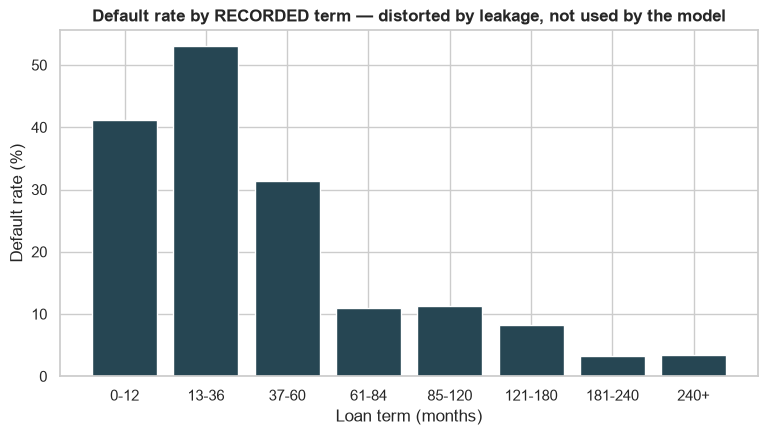

In [2]:
loans = prep.load_clean()
light_style()

# default rate for groups of recorded term
term_groups = pd.cut(loans["Term"], [0, 12, 36, 60, 84, 120, 180, 240, 1000],
                     labels=["0-12", "13-36", "37-60", "61-84", "85-120", "121-180", "181-240", "240+"])
rate = loans.groupby(term_groups, observed=True)["default"].mean() * 100

figure, axis = plt.subplots(figsize=(9, 4.5))
axis.bar(rate.index.astype(str), rate, color="#264653")
axis.set_xlabel("Loan term (months)")
axis.set_ylabel("Default rate (%)")
axis.set_title("Default rate by RECORDED term — distorted by leakage, not used by the model", fontweight="bold")
save_chart("04_default_by_term")

## Evidence A — one month changes everything

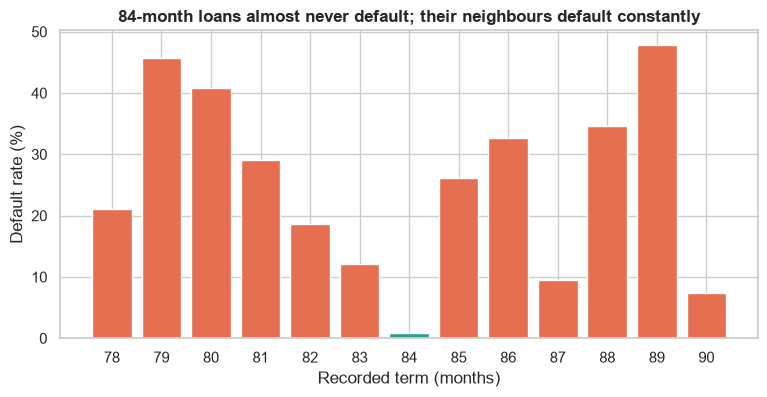

In [3]:
near_84 = loans[(loans["Term"] >= 78) & (loans["Term"] <= 90)]
rate = near_84.groupby("Term")["default"].mean() * 100

colours = []
for term in rate.index:
    if term == 84:
        colours.append("#2a9d8f")
    else:
        colours.append("#e76f51")

figure, axis = plt.subplots(figsize=(9, 4))
axis.bar(rate.index.astype(str), rate, color=colours)
axis.set_xlabel("Recorded term (months)")
axis.set_ylabel("Default rate (%)")
axis.set_title("84-month loans almost never default; their neighbours default constantly", fontweight="bold")
save_chart("24_term_leak_neighbours")

## Evidence B — standard terms belong to repaid loans
## Evidence C — it is not the loan's real life

In [4]:
standard_terms = [12, 24, 36, 48, 60, 72, 84, 96, 108, 120, 180, 240, 300]
loans["standard_term"] = loans["Term"].isin(standard_terms)

share_standard = loans.groupby("default")["standard_term"].mean()
rate_by_standard = loans.groupby("standard_term")["default"].mean()
print("repaid loans with a standard term:   ", round(share_standard[0] * 100, 1), "%")
print("defaulted loans with a standard term:", round(share_standard[1] * 100, 1), "%")

# compare the recorded term of failed loans with how long they really lasted
failed = stats.durations(extra_columns=["Term"])
failed = failed[failed["failed"] == 1]
correlation_with_real_life = pd.to_numeric(failed["Term"]).corr(failed["duration"])
print("correlation between recorded term and real life:", round(correlation_with_real_life, 3))

repaid loans with a standard term:    83.9 %
defaulted loans with a standard term: 9.6 %


correlation between recorded term and real life: 0.053


## Evidence D — `Term` alone predicts almost perfectly

Term                 0.808
ApprovalFY           0.693
SBA_Appv             0.657
GrAppv               0.644
same_state           0.628
DisbursementGross    0.618
guarantee_ratio      0.617
RetainedJob          0.611
dtype: float64


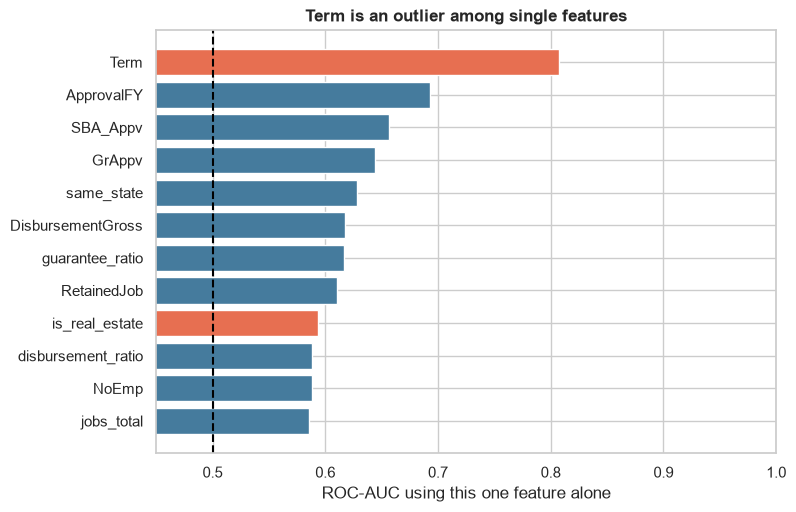

In [5]:
from sklearn.metrics import roc_auc_score
loans["is_real_estate"] = (loans["Term"] >= 240).astype(int)

# ROC-AUC of every single column on its own (0.5 = useless, 1.0 = perfect)
single_scores = {}
for column in loans.select_dtypes("number").columns:
    if column == "default":
        continue
    values = loans[column].fillna(loans[column].median())
    score = roc_auc_score(loans["default"], values)
    single_scores[column] = max(score, 1 - score)       # a column can predict in either direction
single_scores = pd.Series(single_scores).sort_values(ascending=False)
print(single_scores.round(3).head(8))

top_12 = single_scores.head(12)[::-1]
colours = []
for column in top_12.index:
    if column in ["Term", "is_real_estate"]:
        colours.append("#e76f51")
    else:
        colours.append("#457b9d")
figure, axis = plt.subplots(figsize=(8, 5.5))
axis.barh(top_12.index, top_12, color=colours)
axis.axvline(0.5, color="black", ls="--")
axis.set_xlim(0.45, 1)
axis.set_xlabel("ROC-AUC using this one feature alone")
axis.set_title("Term is an outlier among single features", fontweight="bold")
save_chart("25_term_leak_single_feature")

## Impact, cross-validation and out-of-time test
Same forest and split as the baseline. The only change: is `Term` allowed in or not?

In [6]:
from sklearn.model_selection import StratifiedKFold
X_train, X_test, y_train, y_test = train.split(test_share=0.2)
encoder = prep.fit_encoder(X_train, y_train)

def encode_with_term(X):
    """Normal encoding, then put Term (and is_real_estate) back where they used to be."""
    encoded = prep.encode(X, encoder)
    encoded.insert(1, "Term", X["Term"].values)
    encoded.insert(14, "is_real_estate", (X["Term"] >= 240).astype(int).values)
    return encoded

impact = {}
# 1) with Term
forest = train.make_forest(min_loans_per_leaf=5).fit(encode_with_term(X_train), y_train)
probability = forest.predict_proba(encode_with_term(X_test))[:, 1]
caught = ((probability >= 0.5) & (y_test == 1)).sum() / (y_test == 1).sum()
impact["with Term (original project)"] = {"roc_auc": round(roc_auc_score(y_test, probability), 4),
                                          "recall": round(float(caught), 4)}
# 2) without Term (the honest version)
forest = train.make_forest(min_loans_per_leaf=5).fit(prep.encode(X_train, encoder), y_train)
probability = forest.predict_proba(prep.encode(X_test, encoder))[:, 1]
caught = ((probability >= 0.5) & (y_test == 1)).sum() / (y_test == 1).sum()
impact["without Term (honest)"] = {"roc_auc": round(roc_auc_score(y_test, probability), 4),
                                   "recall": round(float(caught), 4)}
print(impact)

def train_and_score(X_a, y_a, X_b, y_b):
    """Train on (X_a, y_a), return the ROC-AUC on (X_b, y_b)."""
    encoder_a = prep.fit_encoder(X_a, y_a)
    forest = train.make_forest(min_loans_per_leaf=5).fit(prep.encode(X_a, encoder_a), y_a)
    probability = forest.predict_proba(prep.encode(X_b, encoder_a))[:, 1]
    return roc_auc_score(y_b, probability)

X = loans.drop(columns=["default", "is_real_estate", "standard_term"])
y = loans["default"]

# 5-fold cross-validation on 300,000 loans
sample = X.sample(300_000, random_state=train.RANDOM_SEED).index
X_sample = X.loc[sample]
y_sample = y.loc[sample]
folds = StratifiedKFold(5, shuffle=True, random_state=train.RANDOM_SEED)
cv_scores = []
for train_rows, test_rows in folds.split(X_sample, y_sample):
    score = train_and_score(X_sample.iloc[train_rows], y_sample.iloc[train_rows],
                            X_sample.iloc[test_rows], y_sample.iloc[test_rows])
    cv_scores.append(score)

# out-of-time: learn from loans up to 2006, test on 2007 onwards
past = X["ApprovalFY"] <= 2006
future = X["ApprovalFY"] >= 2007
out_of_time = train_and_score(X[past], y[past], X[future], y[future])
print("5-fold CV:", round(np.mean(cv_scores), 4), "±", round(np.std(cv_scores), 4),
      "| out-of-time:", round(out_of_time, 4))

summary = {
    "evidence": {"default_rate_standard_term": round(float(rate_by_standard[True]), 4),
                 "default_rate_nonstandard_term": round(float(rate_by_standard[False]), 4),
                 "repaid_with_standard_term": round(float(share_standard[0]), 4),
                 "defaulted_with_standard_term": round(float(share_standard[1]), 4),
                 "term_vs_actual_life_corr": round(float(correlation_with_real_life), 4),
                 "single_feature_auc_term": round(float(single_scores["Term"]), 4),
                 "single_feature_auc_next_best": round(float(single_scores.drop(["Term", "is_real_estate"]).iloc[0]), 4)},
    "impact": impact,
    "cv_5fold_roc_auc_mean": round(float(np.mean(cv_scores)), 4),
    "cv_5fold_roc_auc_std": round(float(np.std(cv_scores)), 4),
    "out_of_time_roc_auc": round(float(out_of_time), 4),
}
(prep.PROJECT_FOLDER / "outputs" / "term_leakage.json").write_text(json.dumps(summary, indent=2))

{'with Term (original project)': {'roc_auc': 0.9757, 'recall': 0.888}, 'without Term (honest)': {'roc_auc': 0.8421, 'recall': 0.6776}}


5-fold CV: 0.8358 ± 0.002 | out-of-time: 0.7746


614